# Projeto de Fusão de Informação em Análises de Dados

<div style="width: 100%; overflow: hidden;">

    <a href="http://www.uc.pt/fctuc/dei/">

    <div style="display: block;margin-left: auto;margin-right: auto; width: 100%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>

    </a>

</div>

---

#### Afonso Rodrigues -- 2020242400 <p>Emanuel Pacheco -- 2024138898


### Criação dos dados artificiais para serem utilizados no projeto
#### Professora aconselhou aos dados terem de ser criados por nós, uma vez que não são entregues no enunciado

In [142]:
import numpy as np
import matplotlib.pyplot as plt

In [143]:
# Parâmetros da trajetória
theta = np.linspace(-np.pi/2, np.pi+0.25, 100)  # Ângulo de 90° a 360°
radius = 10  # Raio do quase-círculo
center = (0,10)  # Centro do círculo

# Gerar a trajetória quase-circular
x = radius * np.cos(theta) + center[0]
y = radius * np.sin(theta) + center[1]
# Time vector (assuming constant speed)
time = np.linspace(0, 10, len(theta))  # Assuming a time vector from 0 to 10 seconds
speed = np.full(len(time), 1.5)  # Assuming a constant speed of 1.5 units


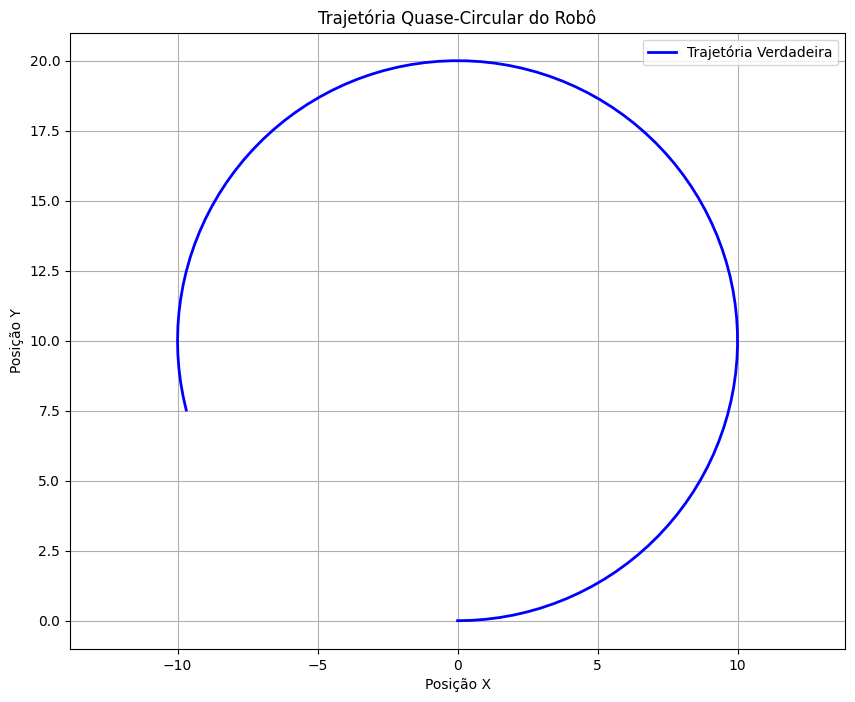

In [144]:
# Função para plotar a trajetória e as elipses de covariância
def plot_trajectory(x, y):
    plt.figure(figsize=(10, 8))
    
    # Trajetória verdadeira
    plt.plot(x, y, 'b-', label='Trajetória Verdadeira', linewidth=2)
    
    plt.xlabel('Posição X')
    plt.ylabel('Posição Y')
    plt.title('Trajetória Quase-Circular do Robô')
    plt.legend()
    plt.grid(True)
    plt.axis('equal')
    plt.show()
    
plot_trajectory(x, y)

#### CSV files creation

In [145]:
import os
if not os.path.exists('robot_trajectory.csv'):
   # Combine time, x, y, and theta into a single 2D array
   data = np.column_stack((time, x, y, theta))

   # Save the data to a CSV file
   np.savetxt('robot_trajectory.csv', 
              np.array([x, y, theta, speed]).T, 
              delimiter=',', header='x,y,orientation,speed', comments='')

   print("CSV file 'robot_trajectory.csv' has been generated.")

print ("robot_trajectory.csv already exists. Skipping the generation of the file.")
   
if not os.path.exists('sensor_data.csv'):
   
   # Save the sensor data to a CSV file
   data = np.column_stack((time, speed, theta))
   np.savetxt('sensor_data.csv', 
              np.array([speed, theta]).T, 
              delimiter=',', header='speed,orientation', comments='')
   
   print("CSV file 'sensor_data.csv' has been generated.")
print ("sensor_data.csv already exists. Skipping the generation of the file.")   


robot_trajectory.csv already exists. Skipping the generation of the file.
sensor_data.csv already exists. Skipping the generation of the file.


In [146]:
# In case of needing to override previous defined files

np.savetxt('robot_trajectory.csv', np.array([x, y, (theta), speed]).T,  delimiter=',', header='x,y,orientation,speed', comments='')
np.savetxt('sensor_data.csv', np.array([speed, (theta)]).T, delimiter=',', header='speed,orientation', comments='')

In [147]:
gnss_data = np.loadtxt("gnss_data.csv", delimiter=",",skiprows=1)
x_gnss = gnss_data[:,0]
y_gnss = gnss_data[:,1]

robot_trajectory = np.loadtxt("robot_trajectory.csv", delimiter=",",skiprows=1)
x_true = robot_trajectory[:,0]
y_true = robot_trajectory[:,1]
orientation = robot_trajectory[:,2]
velocity = robot_trajectory[:,3]

sensor_data = np.loadtxt("sensor_data.csv", delimiter=",",skiprows=1)
speed = sensor_data[:,0]
orientation = sensor_data[:,1]
time_step = time[2] - time[1]
# xk = np.a

In [148]:
A = np.array(([1, 0, 0, 0],
             [0, 1, 0, 0],
             [0, 0, 1, 0],
             [0, 0, 0, 0]))

def get_B(time_step, degree):
   rad = (degree)
   return np.array(([time_step*np.cos(rad), 0],
                    [time_step*np.sin(rad), 0],
                    [0, time_step],
                    [1, 0]))

x_k = robot_trajectory[0]
u_k = sensor_data[0]

B = get_B(time_step, x_k[2])
x_k1 = A @ x_k + B @ u_k

print(x_k1)

[ 6.21601027e-16 -1.51515152e-01 -1.72946262e+00  1.50000000e+00]


In [149]:
# Define the robot dynamic model function
def robot_dynamic_model(x, uk, dt):
    # Robot dynamic model.
    # x: state vector [x, y, phi, v]
    # uk: input vector [v, omega]
    # dt: time step
    xk = np.zeros_like(x)
    xk[0] = x[0] + x[3] * np.cos(x[2]) * dt  # x position
    xk[1] = x[1] + x[3] * np.sin(x[2]) * dt  # y position
    xk[2] = x[2] + uk[1] * dt  # orientation (phi)
    xk[3] = uk[0]  # velocity (v)
    return xk

In [161]:
def observation_model_gps(xk):
    # Observation model.
    # x: state vector [x, y, phi, v]
    gps = [xk[0],xk[1]]
    gps[0] = gps[0] + np.random.choice([-1, 1])*gps[0]*np.random.uniform(0, 0.1)
    gps[1] = gps[1] + np.random.choice([-1, 1])*gps[1]*np.random.uniform(0, 0.1)
    return gps  # Only observe x and y position

In [150]:
# Initialize skib array
skib = np.zeros((100, 4))
skib[0] = robot_trajectory[0]

def recursive_prediction(limit=100, current_depth=0):
    x_k = robot_trajectory[current_depth]
    if current_depth + 1 == limit:
        print("Limit reached")
        return

    u_k = sensor_data[current_depth]
    
    # Use the robot dynamic model to update the state vector
    x_k1 = robot_dynamic_model(x_k, u_k, time_step)
    skib[current_depth + 1] = x_k1
    
    return recursive_prediction(limit, current_depth + 1)

x_k0 = robot_trajectory[0]

recursive_prediction()

Limit reached


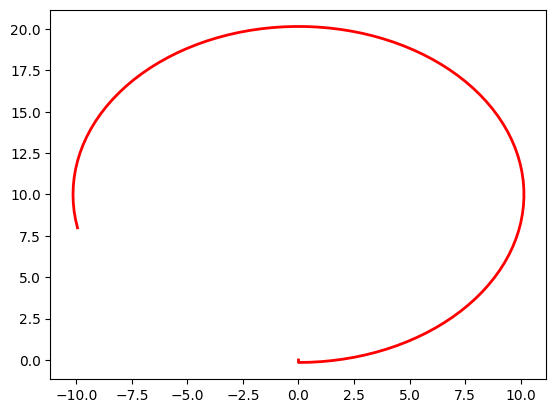

In [151]:
plt.plot(skib[:,0], skib[:,1], 'r-', label='Trajetória Estimada', linewidth=2)

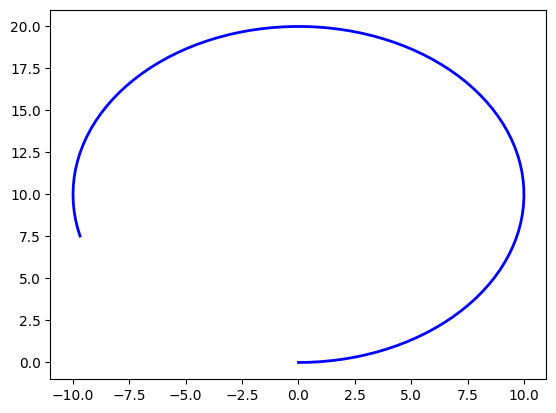

In [160]:
plt.plot(robot_trajectory[:,0], robot_trajectory[:,1], 'b-', label='Trajetória Verdadeira', linewidth=2)

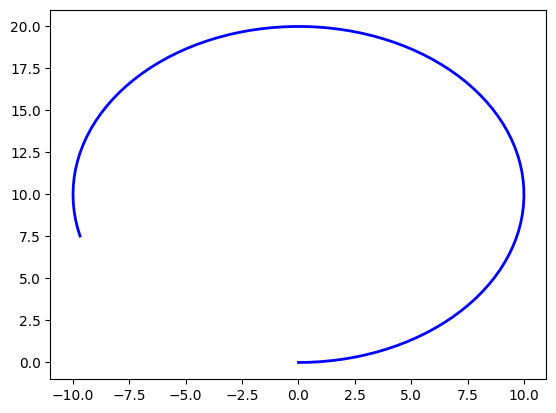

In [153]:
plt.plot(robot_trajectory[:,0], robot_trajectory[:,1], 'b-', label='Trajetória Verdadeira', linewidth=2)

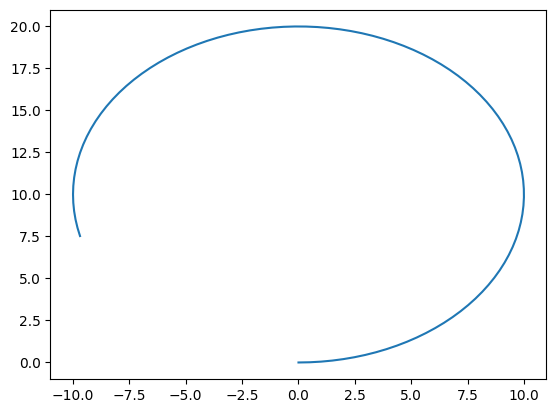

In [154]:
plt.plot(robot_trajectory[:,0], robot_trajectory[:,1], label="True trajectory")

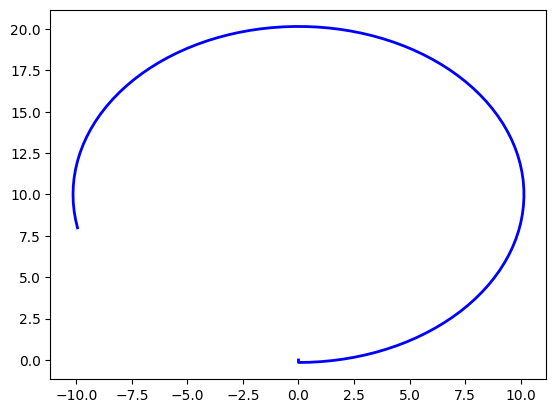

In [155]:
plt.plot(skib[:,0], skib[:,1], 'b-', label='Trajetória prevista', linewidth=2)

In [156]:
skib[:,0]

array([ 6.12323400e-16,  6.21601027e-16,  5.08633075e-01,  1.01598846e+00,
        1.52079168e+00,  2.02177467e+00,  2.51767895e+00,  3.00725881e+00,
        3.48928443e+00,  3.96254495e+00,  4.42585154e+00,  4.87804038e+00,
        5.31797556e+00,  5.74455196e+00,  6.15669803e+00,  6.55337846e+00,
        6.93359677e+00,  7.29639786e+00,  7.64087037e+00,  7.96614898e+00,
        8.27141660e+00,  8.55590639e+00,  8.81890371e+00,  9.05974791e+00,
        9.27783399e+00,  9.47261412e+00,  9.64359901e+00,  9.79035913e+00,
        9.91252584e+00,  1.00097922e+01,  1.00819140e+01,  1.01287100e+01,
        1.01500626e+01,  1.01459182e+01,  1.01162872e+01,  1.00612441e+01,
        9.98092710e+00,  9.87553796e+00,  9.74534144e+00,  9.59066458e+00,
        9.41189594e+00,  9.20948458e+00,  8.98393896e+00,  8.73582565e+00,
        8.46576792e+00,  8.17444414e+00,  7.86258613e+00,  7.53097727e+00,
        7.18045057e+00,  6.81188656e+00,  6.42621105e+00,  6.02439288e+00,
        5.60744142e+00,  

In [157]:
skib[:,0]

array([ 6.12323400e-16,  6.21601027e-16,  5.08633075e-01,  1.01598846e+00,
        1.52079168e+00,  2.02177467e+00,  2.51767895e+00,  3.00725881e+00,
        3.48928443e+00,  3.96254495e+00,  4.42585154e+00,  4.87804038e+00,
        5.31797556e+00,  5.74455196e+00,  6.15669803e+00,  6.55337846e+00,
        6.93359677e+00,  7.29639786e+00,  7.64087037e+00,  7.96614898e+00,
        8.27141660e+00,  8.55590639e+00,  8.81890371e+00,  9.05974791e+00,
        9.27783399e+00,  9.47261412e+00,  9.64359901e+00,  9.79035913e+00,
        9.91252584e+00,  1.00097922e+01,  1.00819140e+01,  1.01287100e+01,
        1.01500626e+01,  1.01459182e+01,  1.01162872e+01,  1.00612441e+01,
        9.98092710e+00,  9.87553796e+00,  9.74534144e+00,  9.59066458e+00,
        9.41189594e+00,  9.20948458e+00,  8.98393896e+00,  8.73582565e+00,
        8.46576792e+00,  8.17444414e+00,  7.86258613e+00,  7.53097727e+00,
        7.18045057e+00,  6.81188656e+00,  6.42621105e+00,  6.02439288e+00,
        5.60744142e+00,  

In [158]:
robot_trajectory

array([[ 6.12323400e-16,  0.00000000e+00, -1.57079633e+00,
         1.50000000e+00],
       [ 5.01041537e-01,  1.25600188e-02, -1.52067119e+00,
         1.50000000e+00],
       [ 1.00082446e+00,  5.02085244e-02, -1.47054604e+00,
         1.50000000e+00],
       [ 1.49809330e+00,  1.12850944e-01, -1.42042090e+00,
         1.50000000e+00],
       [ 1.99159893e+00,  2.00329918e-01, -1.37029576e+00,
         1.50000000e+00],
       [ 2.48010165e+00,  3.12425701e-01, -1.32017062e+00,
         1.50000000e+00],
       [ 2.96237435e+00,  4.48856707e-01, -1.27004548e+00,
         1.50000000e+00],
       [ 3.43720555e+00,  6.09280221e-01, -1.21992034e+00,
         1.50000000e+00],
       [ 3.90340249e+00,  7.93293258e-01, -1.16979520e+00,
         1.50000000e+00],
       [ 4.35979405e+00,  1.00043358e+00, -1.11967006e+00,
         1.50000000e+00],
       [ 4.80523380e+00,  1.23018084e+00, -1.06954491e+00,
         1.50000000e+00],
       [ 5.23860279e+00,  1.48195792e+00, -1.01941977e+00,
      

In [159]:
a[3] = 4

NameError: name 'a' is not defined

In [ ]:
x_k1